In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os

In [2]:
pip install opencv-python

Note: you may need to restart the kernel to use updated packages.


In [3]:
import keras
import seaborn as sns
import matplotlib.pyplot as plt
from keras.models import Sequential
import PIL
import os 
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from PIL import Image
from keras.layers import Conv2D,Flatten,Dense,Dropout,BatchNormalization,MaxPooling2D
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator 
from keras.callbacks import EarlyStopping,ModelCheckpoint
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from tqdm import tqdm
from imblearn.over_sampling import SMOTE

In [4]:
non_demented = []
very_mild_demented = []
mild_demented = []
moderate_demented = []

# Download per category
for dirname, _, filenames in os.walk('C:/Users/sanja/Desktop/AD_DATASET/Data/Non Demented'):
    for filename in filenames:
        non_demented.append(os.path.join(dirname, filename))
        
for dirname, _, filenames in os.walk('C:/Users/sanja/Desktop/AD_DATASET/Data/Very mild Dementia'):
    for filename in filenames:
        very_mild_demented.append(os.path.join(dirname, filename))
        
for dirname, _, filenames in os.walk('C:/Users/sanja/Desktop/AD_DATASET/Data/Mild Dementia'):
    for filename in filenames:
        mild_demented.append(os.path.join(dirname, filename))
        
for dirname, _, filenames in os.walk('C:/Users/sanja/Desktop/AD_DATASET/Data/Moderate Dementia'):
    for filename in filenames:
        moderate_demented.append(os.path.join(dirname, filename))

In [5]:
images = []
labels = []
for subfolder in tqdm(os.listdir("C:/Users/sanja/Desktop/AD_DATASET")):
    subfolder_path = os.path.join("C:/Users/sanja/Desktop/AD_DATASET", subfolder)
    for folder in os.listdir(subfolder_path):
        subfolder_path2=os.path.join(subfolder_path,folder)
        for image_filename in os.listdir(subfolder_path2):
            image_path = os.path.join(subfolder_path2, image_filename)
            images.append(image_path)
            labels.append(folder)
df = pd.DataFrame({'image': images, 'label': labels})
df

100%|██████████| 1/1 [00:00<00:00,  3.40it/s]


,image,label
0,C:/Users/sanja/Desktop/AD_DATASET\Data\Mild De...,Mild Dementia
1,C:/Users/sanja/Desktop/AD_DATASET\Data\Mild De...,Mild Dementia
2,C:/Users/sanja/Desktop/AD_DATASET\Data\Mild De...,Mild Dementia
3,C:/Users/sanja/Desktop/AD_DATASET\Data\Mild De...,Mild Dementia
4,C:/Users/sanja/Desktop/AD_DATASET\Data\Mild De...,Mild Dementia
...,...,...
86432,C:/Users/sanja/Desktop/AD_DATASET\Data\Very mi...,Very mild Dementia
86433,C:/Users/sanja/Desktop/AD_DATASET\Data\Very mi...,Very mild Dementia
86434,C:/Users/sanja/Desktop/AD_DATASET\Data\Very mi...,Very mild Dementia
86435,C:/Users/sanja/Desktop/AD_DATASET\Data\Very mi...,Very mild Dementia


C:\Users\sanja\AppData\Local\Temp\ipykernel_19848\1748014159.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=df.label,palette='Set1')


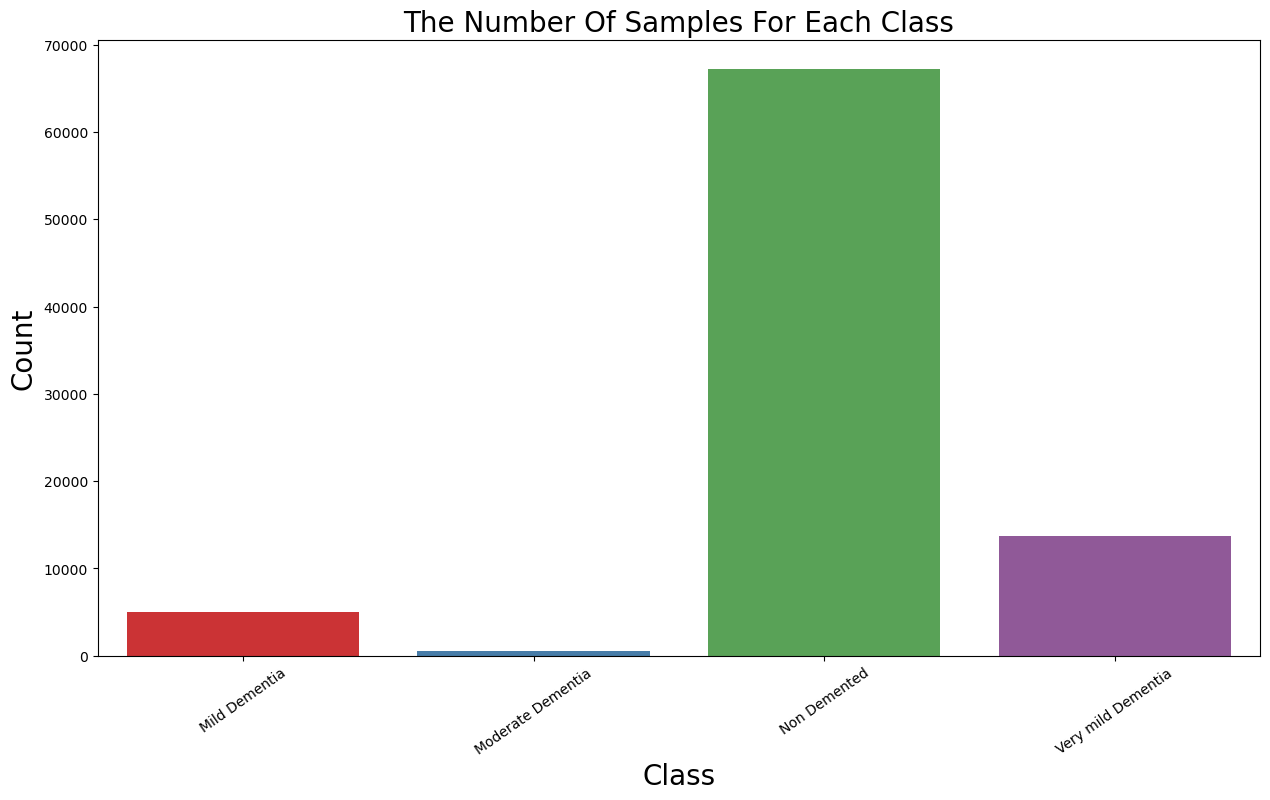

In [6]:
plt.figure(figsize=(15,8))
ax = sns.countplot(x=df.label,palette='Set1')
ax.set_xlabel("Class",fontsize=20)
ax.set_ylabel("Count",fontsize=20)
plt.title('The Number Of Samples For Each Class',fontsize=20)
plt.grid(False)
plt.xticks(rotation=35)
plt.show()

C:\Users\sanja\AppData\Local\Temp\ipykernel_19848\1748014159.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=df.label,palette='Set1')


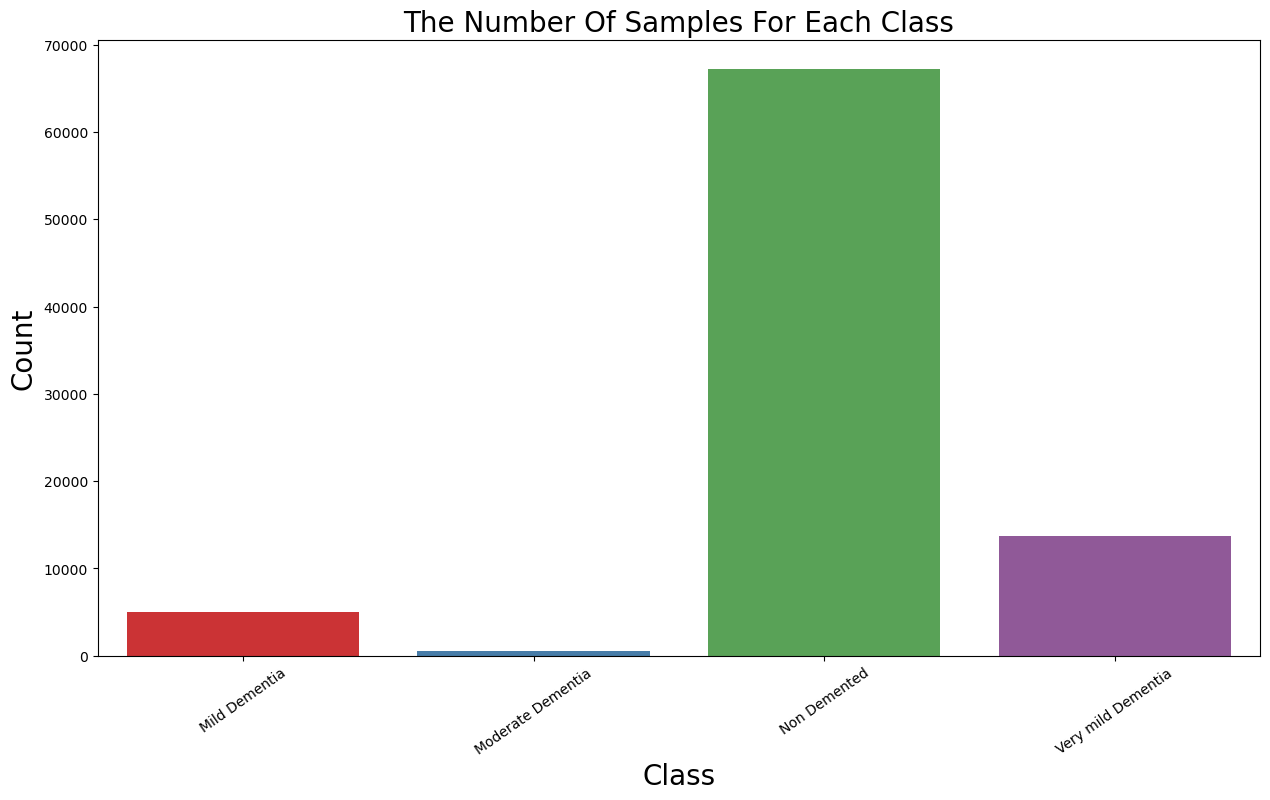

In [7]:
plt.figure(figsize=(15,8))
ax = sns.countplot(x=df.label,palette='Set1')
ax.set_xlabel("Class",fontsize=20)
ax.set_ylabel("Count",fontsize=20)
plt.title('The Number Of Samples For Each Class',fontsize=20)
plt.grid(False)
plt.xticks(rotation=35)
plt.show()

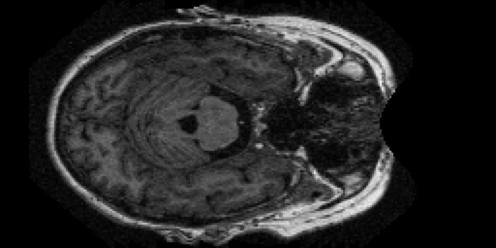

In [8]:
PIL.Image.open(str(non_demented[0]))

In [9]:
print(len(non_demented))
print(len(mild_demented))
print(len(moderate_demented))
print(len(very_mild_demented))

67222
5002
488
13725


In [10]:
# non_demented=non_demented[0:488]
# mild_demented=mild_demented[0:488]
# very_mild_demented=very_mild_demented[0:488]

In [11]:
encoder= OneHotEncoder()
encoder.fit([[0],[1],[2],[3]])

OneHotEncoder()

In [12]:
data = []
result = []
for s in non_demented:
    img = Image.open(s)
    img = img.resize((128,128))
    img = np.array(img)
    if(img.shape == (128,128,3)):
        data.append(np.array(img))
        result.append(encoder.transform([[0]]).toarray())
        
for s in mild_demented:
    img = Image.open(s)
    img = img.resize((128,128))
    img = np.array(img)
    if(img.shape == (128,128,3)):
        data.append(np.array(img))
        result.append(encoder.transform([[1]]).toarray())

for s in moderate_demented:
    img = Image.open(s)
    img = img.resize((128,128))
    img = np.array(img)
    if(img.shape == (128,128,3)):
        data.append(np.array(img))
        result.append(encoder.transform([[2]]).toarray())

for s in very_mild_demented:
    img = Image.open(s)
    img = img.resize((128,128))
    img = np.array(img)
    if(img.shape == (128,128,3)):
        data.append(np.array(img))
        result.append(encoder.transform([[3]]).toarray())

In [13]:
X=np.array(data)

In [14]:
X.shape

(86437, 128, 128, 3)

In [15]:
y=np.array(result)
y=y.reshape(X.shape[0],4)
y=np.argmax(y, axis=1)
y

array([0, 0, 0, ..., 3, 3, 3])

In [16]:
#Performing over-sampling of the data, since the classes are imbalanced

# import imblearn
# smote = imblearn.over_sampling.SMOTE(random_state=42)
# X, y = smote.fit_resample(X.reshape(-1, 128 * 128 * 3), y)
# X = X.reshape(-1, 128,128, 3)
# print(X.shape, y.shape)

#Performing over-sampling of the data, since the classes are imbalanced

# import imblearn
# smote = imblearn.over_sampling.SMOTE(random_state=42)
# train_images, train_labels = smote.fit_resample(train_images.reshape(-1, 176 * 176 * 3), train_labels)
# train_images = train_images.reshape(-1, 176,176, 3)
# print(train_images.shape, train_labels.shape)

In [17]:
X_train,X_test,y_train,y_test= train_test_split(X,y,test_size=0.2,random_state=42, shuffle = True)

In [18]:
X_train.shape

(69149, 128, 128, 3)

In [19]:
X_test.shape

(17288, 128, 128, 3)

In [20]:
model=Sequential()

In [21]:
model.add(Conv2D(filters=32,kernel_size=2,padding='Same',input_shape = (128,128,3)))

C:\Users\sanja\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [22]:
model.add(Conv2D(filters=32,kernel_size=2,padding='Same',activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),strides=(2,2)))
model.add(Dropout(0.25))
model.add(Conv2D(filters=64,kernel_size=2,padding='Same',activation='relu'))
model.add(Conv2D(filters=64,kernel_size=2,padding='Same',activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),strides=(2,2)))
model.add(Dropout(0.25))
model.add(Conv2D(filters=128,kernel_size=2,padding='Same',activation='relu'))
model.add(Conv2D(filters=128,kernel_size=2,padding='Same',activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),strides=(2,2)))
model.add(Dropout(0.25))


model.add(Flatten())
model.add(Dense(256,activation='relu'))
model.add(Dropout(0.25))
model.add(Dense(4,activation='softmax'))

In [23]:
print(model.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,518,596 (32.50 MB)

 Trainable params: 8,518,148 (32.49 MB)

 Non-trainable params: 448 (1.75 KB)

None


In [24]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [25]:
from keras.callbacks import EarlyStopping
early_stopping=EarlyStopping(
    monitor="val_loss",
    min_delta=0.00001,
    patience=20,
    verbose=0,
    mode="auto",
    baseline=None,
    restore_best_weights=True,
    start_from_epoch=0,
)

In [26]:
history= model.fit(X_train,y_train, validation_split=0.2,epochs=5,callbacks=[early_stopping],batch_size=128)

Epoch 1/5
433/433 ━━━━━━━━━━━━━━━━━━━━ 817s 2s/step - accuracy: 0.8042 - loss: 0.8788 - val_accuracy: 0.8535 - val_loss: 0.3392
Epoch 2/5
433/433 ━━━━━━━━━━━━━━━━━━━━ 794s 2s/step - accuracy: 0.8910 - loss: 0.2553 - val_accuracy: 0.9337 - val_loss: 0.1649
Epoch 3/5
433/433 ━━━━━━━━━━━━━━━━━━━━ 793s 2s/step - accuracy: 0.9333 - loss: 0.1607 - val_accuracy: 0.9800 - val_loss: 0.0599
Epoch 4/5
433/433 ━━━━━━━━━━━━━━━━━━━━ 820s 2s/step - accuracy: 0.9560 - loss: 0.1077 - val_accuracy: 0.9828 - val_loss: 0.0469
Epoch 5/5
433/433 ━━━━━━━━━━━━━━━━━━━━ 806s 2s/step - accuracy: 0.9648 - loss: 0.0899 - val_accuracy: 0.9813 - val_loss: 0.0498


In [27]:
model.evaluate(X_test,y_test)

541/541 ━━━━━━━━━━━━━━━━━━━━ 40s 74ms/step - accuracy: 0.9836 - loss: 0.0452


[0.045213647186756134, 0.9836302399635315]

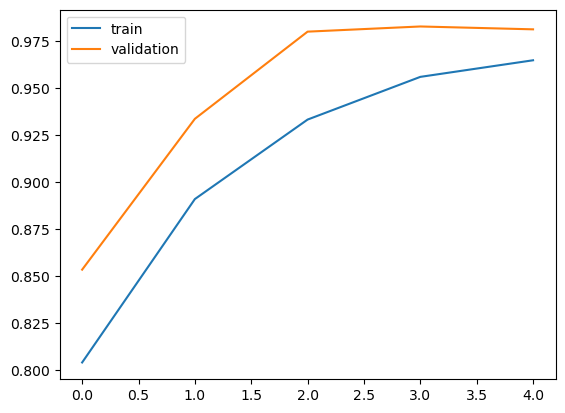

In [28]:
%matplotlib inline 
plt.plot(history.history['accuracy'],label='train')
plt.plot(history.history['val_accuracy'],label='validation')
plt.legend()
plt.show()

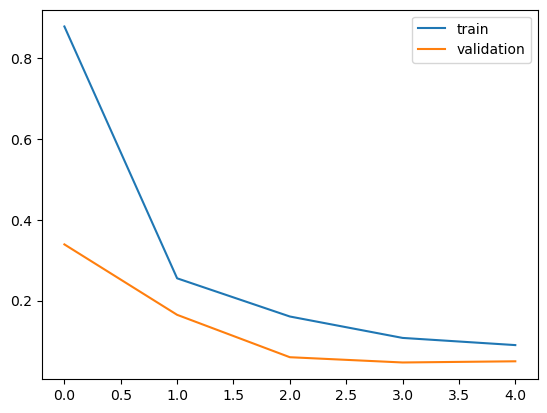

In [29]:
plt.plot(history.history['loss'],label='train')
plt.plot(history.history['val_loss'],label='validation')
plt.legend()
plt.show()

In [30]:
#classes names 
class_name = {0: "Mild Dementia",1: "Moderate Dementia" , 2: "Non Demented", 3: "Very mild Dementia"}

In [31]:
test_scores = model.evaluate(X_test,y_test)
test_scores

541/541 ━━━━━━━━━━━━━━━━━━━━ 40s 73ms/step - accuracy: 0.9836 - loss: 0.0452


[0.045213647186756134, 0.9836302399635315]

In [32]:
predicted_test_labels = model.predict(X_test)
res = model.predict(X_test)
predicted_test_labels =  np.argmax(predicted_test_labels,axis= 1 )
predicted_test_labels[1]

541/541 ━━━━━━━━━━━━━━━━━━━━ 39s 72ms/step
541/541 ━━━━━━━━━━━━━━━━━━━━ 39s 73ms/step


np.int64(0)

In [33]:
ypred = []
for i in res:
  temp = np.argmax(i)
  ypred.append(temp)
ypred = np.array(ypred)

In [34]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score

accuracy_score(y_test,ypred)

0.9836302637667746

In [35]:
cf = confusion_matrix(y_true = y_test ,y_pred =  ypred)
plt.figure(figsize=(8, 6), dpi=80, facecolor='w', edgecolor='k')

# ax = sns.heatmap(cf, cmap='Blues', annot=True, fmt='d', xticklabels=class_name, yticklabels=class_name)

# plt.title('Alzheimer\'s Disease Diagnosis')
# plt.xlabel('Prediction')
# plt.ylabel('Truth')
# plt.show(ax)


x = ConfusionMatrixDisplay(cf)
x.plot()

In [36]:
print(classification_report(y_true = y_test ,y_pred =  ypred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99     13476
           1       0.98      0.94      0.96      1006
           2       1.00      0.48      0.65        97
           3       0.95      0.96      0.96      2709

    accuracy                           0.98     17288
   macro avg       0.98      0.85      0.89     17288
weighted avg       0.98      0.98      0.98     17288

